# 19 — MISO and SPP: timing models on the 2026 file (a registered extension)

The 2025 edition of the LBNL file dated almost no MISO or SPP operations, so the project's timing models covered three ISOs. The 2026 edition dates 92% of MISO's operations and 94% of its withdrawals, 95% and 73% of SPP's (notebook 01b). This notebook fits the same models — the fair baseline, the discrete-time logit and LightGBM with notebook 06's settings — for MISO and for SPP on the 2026 file, censored at 2025-12-31, with its own pre-registered criteria written in the first cell (decision #49). The results are reported beside, never pooled with, the three-ISO results on the frozen 2025 file, which stay the project's registered verdict.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/queue_clean_2026.parquet` | notebook 01b — the 2026 edition through rules R2–R9 |
| in | `results/dt_tuning.json`, `results/success_criteria_v2_registered.json` | notebooks 06/11 — settings and bootstrap parameters, reused unchanged |
| out | `results/success_criteria_v3.csv`, `docs/decisions.md` (#54) | criteria C13–C14, written before any metric |
| out | `results/miso_spp_date_coverage.csv`, `results/miso_spp_samples.csv` | what the 2026 file gives each region |
| out | `results/miso_spp_metrics.csv`, `results/success_criteria_v3_scored.csv` | the metrics with intervals and the scored lines |
| out | `data/processed/predictions_miso_spp.parquet` | test predictions |
| out | `figures/F17_miso_spp.*`, `figures/19_miso_spp_timing/*` | F17 and the notebook's figures |
| out | `results/miso_spp_checks.csv` | this notebook's checks |

## 0. Criteria C13–C14, written before anything is fitted

In [1]:
# Pre-registration: this cell reads no data
import json
import re
from pathlib import Path

import pandas as pd

REPO = Path.cwd().resolve().parent
CRITERIA_V3 = [
    {"id": "C13", "region": r, "line": f"{r}: LightGBM vs fair baseline, {m} at {h} years", "metric": m, "horizon": h,
     "rule": "paired 95% interval entirely on the better side"}
    for r in ["MISO", "SPP"] for m in ["uno_c", "brier"] for h in [3, 5]
] + [
    {"id": "C14", "region": r, "line": f"{r}: LightGBM calibration slope at {h} years", "metric": "slope", "horizon": h,
     "rule": "slope interval within 0.8–1.2"} for r in ["MISO", "SPP"] for h in [3, 5]
]
DECISION_54 = """54. **Pre-registered criteria C13–C14 for the MISO and SPP timing models**
    (2026-10-06; written by the first cell of notebook 19 before any MISO or
    SPP model was fitted; follows #49). Data: the 2026 LBNL file censored at
    2025-12-31; one model per region (region pooled, state target-encoded),
    notebook 06's settings unchanged, fitted on entrants to 2016, scored on
    2017–2019 entrants. C13: LightGBM beats the fair baseline (region ×
    technology × size) on Uno's C and Brier at 3 and 5 years, per region,
    with the 95% paired interval on the better side. C14: LightGBM's
    calibration slope interval within 0.8–1.2 at 3 and 5 years, per region.
    Twelve lines; failures reported, not removed; never pooled with the
    three-ISO verdict. MISO's operation-date coverage (92%) is below the
    95% notebook 01 asked of the 2025 file and is stated as a caveat.
"""
decisions_file = REPO / "docs" / "decisions.md"
text = decisions_file.read_text(encoding="utf-8")
if not re.search(r"^54\. \*\*Pre-registered criteria C13", text, re.M):
    decisions_file.write_text(text.rstrip("\n") + "\n" + DECISION_54, encoding="utf-8")
pd.DataFrame(CRITERIA_V3).to_csv(REPO / "results" / "success_criteria_v3.csv", index=False)
print(f"{len(CRITERIA_V3)} criterion lines registered")

12 criterion lines registered


## Setup

In [2]:
import hashlib
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

sys.path.append(str(REPO))
from src import baselines, config, discrete_time, evaluation, events, features, paths, plots, survival_tools

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "19_miso_spp_timing"
REGIONS = ["MISO", "SPP"]
CENSOR_2026 = "2025-12-31"
HORIZONS = [3, 5]
START = time.time()
REGISTERED = json.loads((paths.RESULTS / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
N_BOOT, LEVEL, SEED = REGISTERED["n_boot"], REGISTERED["level"], REGISTERED["seed_v2"] + 500
frozen_hash_before = hashlib.sha256((paths.DATA_PROCESSED / "predictions_trackA.parquet").read_bytes()).hexdigest()


def save(fig, name, caption):
    """Save a figure of this notebook under figures/19_miso_spp_timing/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Samples from the 2026 file

Events are coded against the 2026 file's own end of data collection; the entry-time features are notebook 04's, computed on the 2026 file (congestion counted in its own queue). The modelling sample of each region is its requests with a valid request date and a dated exit (or still active), as Track A was defined.

In [3]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
coded = events.code_events(clean, censor_date=CENSOR_2026)
coded["entry_years"] = 0.0  # no delayed entry: the stamped-date problem was ERCOT's
feature_table = features.build_features(clean)
shared = [c for c in feature_table.columns if c in coded.columns and c not in ("region", "q_year")]
queue = coded.drop(columns=shared).join(feature_table.drop(columns=["region", "q_year"]))
queue["tech"] = queue["type_clean"].map(plots.tech_group)
coverage = []
for region in REGIONS:
    part = queue[queue["region"] == region]
    coverage.append({"region": region, "requests": len(part),
                     "operational with date": float(part.loc[part["q_status"] == "operational", "on_date"].notna().mean()),
                     "withdrawn with date": float(part.loc[part["q_status"] == "withdrawn", "wd_date"].notna().mean()),
                     "usable (no exclusion)": int((part["exclusion"] == "").sum())})
coverage = pd.DataFrame(coverage)
coverage.to_csv(paths.RESULTS / "miso_spp_date_coverage.csv", index=False)
samples = {}
rows = []
for region in REGIONS:
    s = queue[(queue["region"] == region) & (queue["exclusion"] == "")].copy()
    samples[region] = s
    train, test = s[s["q_year"] <= config.TRAIN_MAX_YEAR], s[s["q_year"].between(*config.TEST_YEARS)]
    rows.append({"region": region, "usable requests": len(s), "train (≤ 2016)": len(train), "test (2017–2019)": len(test),
                 "test operations within 5 years": int(((test["event"] == 1) & (test["duration_years"] <= 5)).sum()),
                 "test withdrawals within 5 years": int(((test["event"] == 2) & (test["duration_years"] <= 5)).sum())})
sizes = pd.DataFrame(rows)
sizes.to_csv(paths.RESULTS / "miso_spp_samples.csv", index=False)
display(coverage.round(3))
sizes

,region,requests,operational with date,withdrawn with date,usable (no exclusion)
0,MISO,5414,0.924,0.938,5169
1,SPP,2718,0.946,0.726,2191


,region,usable requests,train (≤ 2016),test (2017–2019),test operations within 5 years,test withdrawals within 5 years
0,MISO,5169,1597,737,54,426
1,SPP,2191,662,448,8,250


**Reading this.** The 2026 file gives MISO 5,169 usable requests (92% of its operations and 94% of its withdrawals dated — the 92% is below the 95% notebook 01 asked of the 2025 file, stated here and accepted) and SPP 2,191 (95% and 73%). The test cohorts are what limits this notebook: MISO's 737 requests of 2017–2019 hold 54 operations within five years and 426 withdrawals; SPP's 448 hold **8** operations and 250 withdrawals. Eight events cannot support a ranking verdict at any horizon, and 54 only a coarse one; the three-ISO test cohort had 227.

## 2. Fits, predictions and scores, per region

One LightGBM and one logit per region, notebook 06's settings, `pool_regions=True` so the region column is constant and the state encoding carries the geography; the fair baseline and the region × technology baseline from the same training requests. Metrics as in notebook 11, with 200 bootstrap resamples and paired differences against the fair baseline.

In [4]:
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
tables, preds_out = [], []
for r_i, region in enumerate(REGIONS):
    s = samples[region]
    train, test = s[s["q_year"] <= config.TRAIN_MAX_YEAR], s[s["q_year"].between(*config.TEST_YEARS)]
    fitted = discrete_time.fit_both(train, clean, tuning, delayed=False, pool_regions=True)
    p = discrete_time.predict_both(fitted, test, horizons=HORIZONS)
    fair = baselines.fair_baseline_cif(train, test, HORIZONS)
    base = survival_tools.baseline_cif(train, test, HORIZONS)
    d, e = test["duration_years"].to_numpy(), test["event"].to_numpy()
    follow_up = ((pd.Timestamp(CENSOR_2026) - test["q_date"]).dt.days / config.DAYS_PER_YEAR).to_numpy()
    G = evaluation.censoring_km(follow_up, np.ones(len(test), bool))
    for h in HORIZONS:
        sub = {"baseline": base[h].to_numpy(), "fair_baseline": fair[h].to_numpy(),
               "dt_logit": p["dt_logit"][h].to_numpy(), "dt_lgbm": p["dt_lgbm"][h].to_numpy()}
        point = evaluation.score_horizon(sub, d, e, h, G)
        draws = evaluation.bootstrap(lambda sw: evaluation.score_horizon(sub, d, e, h, G, sw), len(test), N_BOOT, SEED + 10 * r_i + h)
        t = evaluation.summarise(point, draws, reference="fair_baseline", level=LEVEL)
        t.insert(0, "horizon", h)
        t.insert(0, "region", region)
        tables.append(t)
        f = pd.DataFrame(sub, index=test.index)
        f.insert(0, "horizon", h)
        f.insert(0, "region", region)
        f.insert(0, "project_key", test["project_key"].astype(str).to_numpy())
        f["event"], f["duration_years"], f["q_year"] = e, d, test["q_year"].to_numpy()
        preds_out.append(f)
    print(f"{region}: fitted and scored ({(time.time() - START) / 60:.1f} min)")
metrics = pd.concat(tables, ignore_index=True)
metrics.to_csv(paths.RESULTS / "miso_spp_metrics.csv", index=False)
pd.concat(preds_out, ignore_index=True).to_parquet(paths.DATA_PROCESSED / "predictions_miso_spp.parquet", index=False)
show = metrics[metrics["metric"].isin(["uno_c", "brier", "slope"])].copy()
show["value"] = [f"{r.estimate:.3f} [{r.low:.3f}, {r.high:.3f}]" for r in show.itertuples()]
show.pivot_table(index=["region", "horizon", "metric"], columns="model", values="value", aggfunc="first")[["baseline", "fair_baseline", "dt_logit", "dt_lgbm"]]

MISO: fitted and scored (0.1 min)


C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:138: RuntimeWarning: invalid value encountered in scalar divide
  return float(np.sum(case * (below + 0.5 * control)) / (case.sum() * control.sum()))
C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:281: RuntimeWarning: invalid value encountered in scalar divide
  return {"precision": float(precision), "base_rate": float(base_rate), "lift": float(precision / base_rate)}
C:\Users\alanm\OneDrive\Área de Trabalho\CAPSTONE\src\evaluation.py:186: RuntimeWarning: invalid value encountered in scalar divide
  return float(np.sum(pair * score) / np.sum(pair))


SPP: fitted and scored (0.1 min)


model                               baseline          fair_baseline                dt_logit                dt_lgbm
region horizon metric                                                                                             
MISO   3       brier    0.020 [0.014, 0.027]   0.018 [0.013, 0.025]    0.024 [0.018, 0.030]   0.023 [0.018, 0.029]
               slope    1.108 [0.389, 2.634]   1.206 [0.515, 2.306]    1.291 [0.732, 1.940]   1.870 [0.832, 3.099]
               uno_c    0.711 [0.568, 0.851]   0.802 [0.600, 0.949]    0.826 [0.683, 0.940]   0.813 [0.628, 0.951]
       5       brier    0.077 [0.061, 0.091]   0.077 [0.060, 0.092]    0.083 [0.068, 0.097]   0.092 [0.077, 0.102]
               slope   0.030 [-0.354, 0.457]  0.045 [-0.301, 0.445]    0.369 [0.076, 0.647]  0.298 [-0.138, 0.738]
               uno_c    0.502 [0.440, 0.579]   0.490 [0.421, 0.568]    0.615 [0.549, 0.681]   0.557 [0.485, 0.643]
SPP    3       brier    0.014 [0.010, 0.019]   0.013 [0.009, 0.019]    0.006 [0.002, 0.013]   0.005 [0.001, 0.012]
               slope    1.798 [0.582, 2.510]   1.454 [0.136, 2.193]  -0.229 [-3.554, 2.634]  0.747 [-4.851, 4.276]
               uno_c    0.805 [0.596, 0.992]   0.810 [0.599, 0.992]    0.495 [0.000, 0.991]   0.510 [0.022, 0.993]
       5       brier    0.044 [0.037, 0.051]   0.042 [0.035, 0.049]    0.020 [0.011, 0.030]   0.025 [0.017, 0.035]
               slope    1.808 [0.985, 3.074]   1.474 [0.760, 2.596]   0.947 [-1.015, 2.505]  1.002 [-0.965, 3.621]
               uno_c    0.714 [0.609, 0.833]   0.742 [0.626, 0.842]    0.797 [0.492, 0.945]   0.750 [0.475, 0.938]

**Reading this.** In MISO at 5 years, LightGBM's Uno's C is 0.557 [0.485, 0.643] against the fair baseline's 0.490 — the baseline is at chance because MISO's size and technology cells barely separate its few completions — and the logit does better still (0.615); but both models' Brier scores are *worse* than the baselines' (0.092 against 0.077), because their level is too high for a cohort where 7% operated. At 3 years every MISO model sits at 0.80–0.83 with intervals that overlap entirely. In SPP the Brier scores favour the models (0.005 against 0.013 at 3 years, 0.025 against 0.042 at 5) because the baselines' level is far too high for a cohort with 8 operations, while Uno's C at 3 years is undefined in all but name (0.51 with an interval from 0.02 to 0.99 — three events). The calibration slopes carry intervals several units wide. These are the numbers of a region whose outcomes have only just started to be dated.

## 3. The registered lines

In [5]:
rows = []
for c in CRITERIA_V3:
    r = metrics[(metrics["region"] == c["region"]) & (metrics["model"] == "dt_lgbm") & (metrics["metric"] == c["metric"])
                & (metrics["horizon"] == c["horizon"])].iloc[0]
    if c["id"] == "C13":
        passed = bool(r["beats"])
        rows.append({**c, "estimate": r["estimate"], "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"],
                     "diff_high": r["diff_high"], "result": "PASS" if passed else "FAIL"})
    else:
        passed = 0.8 <= r["low"] and r["high"] <= 1.2
        rows.append({**c, "estimate": r["estimate"], "benchmark": np.nan, "diff": np.nan, "diff_low": r["low"], "diff_high": r["high"],
                     "result": "PASS" if passed else "FAIL"})
scored = pd.DataFrame(rows)
scored.to_csv(paths.RESULTS / "success_criteria_v3_scored.csv", index=False)
n_pass = int((scored["result"] == "PASS").sum())
print(f"{n_pass} of {len(scored)} registered lines pass")
scored[["id", "line", "estimate", "benchmark", "diff", "diff_low", "diff_high", "result"]].round(3)

3 of 12 registered lines pass


,id,line,estimate,benchmark,diff,diff_low,diff_high,result
0,C13,"MISO: LightGBM vs fair baseline, uno_c at 3 years",0.813,0.802,0.011,-0.076,0.091,FAIL
1,C13,"MISO: LightGBM vs fair baseline, uno_c at 5 years",0.557,0.490,0.067,0.008,0.127,PASS
2,C13,"MISO: LightGBM vs fair baseline, brier at 3 years",0.023,0.018,0.005,0.003,0.006,FAIL
3,C13,"MISO: LightGBM vs fair baseline, brier at 5 years",0.092,0.077,0.015,0.010,0.020,FAIL
4,C13,"SPP: LightGBM vs fair baseline, uno_c at 3 years",0.510,0.810,-0.301,-0.622,0.004,FAIL
5,C13,"SPP: LightGBM vs fair baseline, uno_c at 5 years",0.750,0.742,0.009,-0.237,0.200,FAIL
6,C13,"SPP: LightGBM vs fair baseline, brier at 3 years",0.005,0.013,-0.009,-0.012,-0.005,PASS
7,C13,"SPP: LightGBM vs fair baseline, brier at 5 years",0.025,0.042,-0.017,-0.022,-0.012,PASS
8,C14,MISO: LightGBM calibration slope at 3 years,1.870,NaN,NaN,0.832,3.099,FAIL
9,C14,MISO: LightGBM calibration slope at 5 years,0.298,NaN,NaN,-0.138,0.738,FAIL


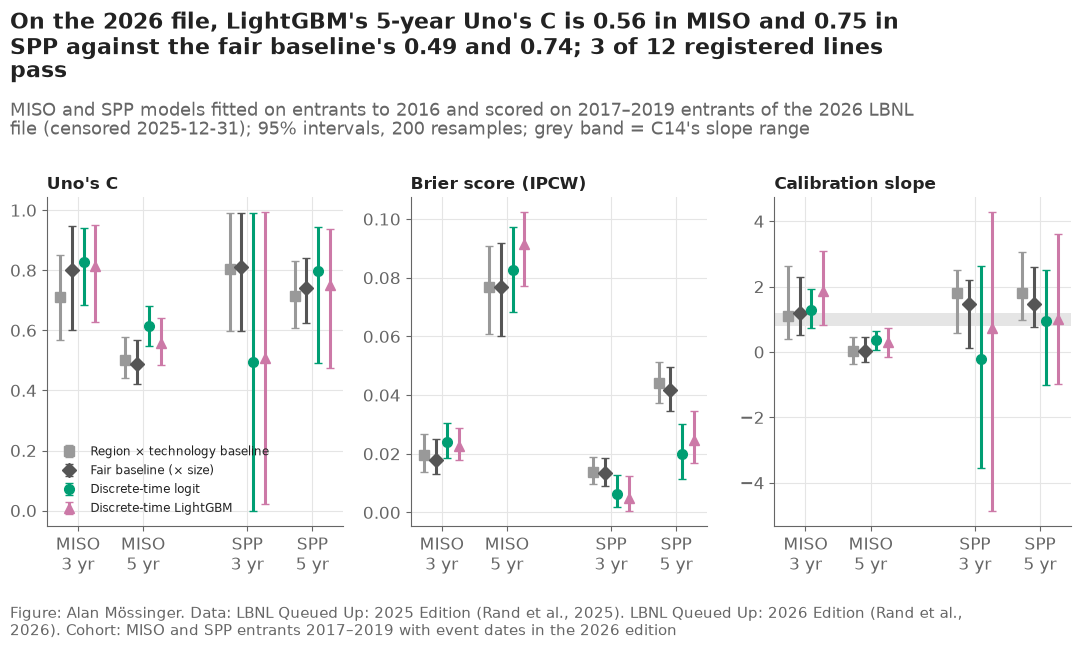

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
style = {"baseline": ("#999999", "s"), "fair_baseline": ("#555555", "D"), "dt_logit": ("#009E73", "o"), "dt_lgbm": ("#CC79A7", "^")}
labels = {"baseline": "Region × technology baseline", "fair_baseline": "Fair baseline (× size)", "dt_logit": "Discrete-time logit", "dt_lgbm": "Discrete-time LightGBM"}
for ax, metric, title in zip(axes, ["uno_c", "brier", "slope"], ["Uno's C", "Brier score (IPCW)", "Calibration slope"]):
    for r_i, region in enumerate(REGIONS):
        for m_i, (model, (color, marker)) in enumerate(style.items()):
            part = metrics[(metrics["region"] == region) & (metrics["model"] == model) & (metrics["metric"] == metric)].set_index("horizon").loc[HORIZONS]
            x = np.array([0, 1]) + r_i * 2.6 + (m_i - 1.5) * 0.18
            ax.errorbar(x, part["estimate"], yerr=[part["estimate"] - part["low"], part["high"] - part["estimate"]], fmt=marker, color=color,
                        capsize=3, markersize=7, label=labels[model] if r_i == 0 else None)
    ax.set_xticks([0, 1, 2.6, 3.6], ["MISO\n3 yr", "MISO\n5 yr", "SPP\n3 yr", "SPP\n5 yr"])
    ax.set_title(title, fontsize=12)
    if metric == "slope":
        ax.axhspan(0.8, 1.2, color="#E5E5E5", zorder=0)
axes[0].legend(fontsize=8.5, loc="lower left")
mm = metrics.set_index(["region", "model", "metric", "horizon"])
plots.finish(fig,
             f"On the 2026 file, LightGBM's 5-year Uno's C is {mm.loc[('MISO', 'dt_lgbm', 'uno_c', 5), 'estimate']:.2f} in MISO and "
             f"{mm.loc[('SPP', 'dt_lgbm', 'uno_c', 5), 'estimate']:.2f} in SPP against the fair baseline's "
             f"{mm.loc[('MISO', 'fair_baseline', 'uno_c', 5), 'estimate']:.2f} and {mm.loc[('SPP', 'fair_baseline', 'uno_c', 5), 'estimate']:.2f}; "
             f"{n_pass} of {len(scored)} registered lines pass",
             f"MISO and SPP models fitted on entrants to 2016 and scored on 2017–2019 entrants of the 2026 LBNL file (censored 2025-12-31); "
             f"95% intervals, {N_BOOT} resamples; grey band = C14's slope range",
             "MISO and SPP entrants 2017–2019 with event dates in the 2026 edition", lbnl_2026=True)
plots.save_fig(fig, "F17_miso_spp", "Uno's C, Brier score and calibration slope of the MISO and SPP timing models at 3 and 5 years, with baselines.", NOTEBOOK)
plt.show()

**Reading this.** Three of the twelve registered lines pass: MISO's 5-year ranking (+0.067 [+0.008, +0.127] over the fair baseline) and SPP's two Brier lines, which say less about ranking than about the baselines' level. Every calibration line fails on width alone. The honest reading is that the 2026 file makes MISO and SPP timing models *possible* and the 2017–2019 cohorts make them *untestable* for now: the regions need two or three more years of dated outcomes before a verdict means anything. The report carries this as what it is — the method transfers, the evidence does not yet — and keeps the three-ISO verdict on the frozen file as the project's result.

## 4. Checks

In [7]:
criteria_written = (paths.RESULTS / "success_criteria_v3.csv").stat().st_mtime
metrics_written = (paths.RESULTS / "miso_spp_metrics.csv").stat().st_mtime
frozen_hash_after = hashlib.sha256((paths.DATA_PROCESSED / "predictions_trackA.parquet").read_bytes()).hexdigest()
checks = pd.DataFrame([
    {"check": "criteria file written before the metrics file", "value": round(metrics_written - criteria_written, 1), "pass": metrics_written > criteria_written},
    {"check": "the frozen pipeline's predictions are untouched", "value": frozen_hash_after[:12], "pass": frozen_hash_after == frozen_hash_before},
    {"check": "every metric row carries an interval", "value": int(metrics[["low", "high"]].isna().any(axis=1).sum()), "pass": not metrics[["low", "high"]].isna().any(axis=1).any()},
    {"check": "one scored row per registered line", "value": len(scored), "pass": len(scored) == len(CRITERIA_V3)},
    {"check": "F17 saved as PNG and SVG", "value": 2, "pass": (paths.FIGURES / "F17_miso_spp.png").exists() and (paths.FIGURES / "F17_miso_spp.svg").exists()},
])
checks.to_csv(paths.RESULTS / "miso_spp_checks.csv", index=False)
assert checks["pass"].all(), checks
print(f"total {(time.time() - START) / 60:.1f} min")
checks

total 0.1 min


,check,value,pass
0,criteria file written before the metrics file,8.8,True
1,the frozen pipeline's predictions are untouched,6e0850d09c32,True
2,every metric row carries an interval,0,True
3,one scored row per registered line,12,True
4,F17 saved as PNG and SVG,2,True


## Takeaways

- The 2026 file dates enough MISO and SPP outcomes to fit the models (5,169 and 2,191 usable requests), but the 2017–2019 test cohorts hold 54 and 8 operations within five years.
- 3 of 12 registered lines pass: MISO's 5-year ranking over the fair baseline (+0.067 [+0.008, +0.127]) and SPP's two Brier lines; every calibration line fails on interval width.
- MISO's models over-predict the level (Brier 0.092 against the baseline's 0.077 at 5 years) as the three-ISO models did; SPP's baselines over-predict it more.
- The frozen pipeline's predictions are untouched (hash checked); nothing here is pooled with the three-ISO verdict.
- **What goes to the report:** F17 and the scored table, as a registered extension whose evidence is not yet there; the data section's statement that MISO and SPP timing becomes testable around 2028.